<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/07_cLab_TcEstudiante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn`
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (ordenada / desordenada) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase ordenada** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase desordenada** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* ordenadas ($y=0$) y *claramente*
desordenadas ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier

RNG = 42
np.random.seed(RNG)

## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = ordenada ($T$ baja), `1` = desordenada ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

In [3]:
# datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
from google.colab import drive
drive.mount('/content/drive')
datos = np.load("/content/drive/MyDrive/Datos/ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]

Tc_exacto = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, "->", np.unique(y, return_counts=True))
print("realizaciones:", np.unique(realizacion))
print("Tc exacto (Onsager):", Tc_exacto)

Mounted at /content/drive
X: (1600, 16, 16) int8
y: (1600,) -> (array([0, 1], dtype=int8), array([800, 800]))
realizaciones: [0 1 2 3]
Tc exacto (Onsager): 2.269185314213022


### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

=== 1. Temperaturas por clase ===
T con y = 0 :  [1.2   1.375 1.55  1.725 1.9  ]
T con y = 1 :  [2.6   2.825 3.05  3.275 3.5  ]
Hueco: no hay datos entre T = 1.900 y T = 2.600

=== 2. Balance de clases ===
  clase 0: 800 configuraciones (50.0 %)
  clase 1: 800 configuraciones (50.0 %)


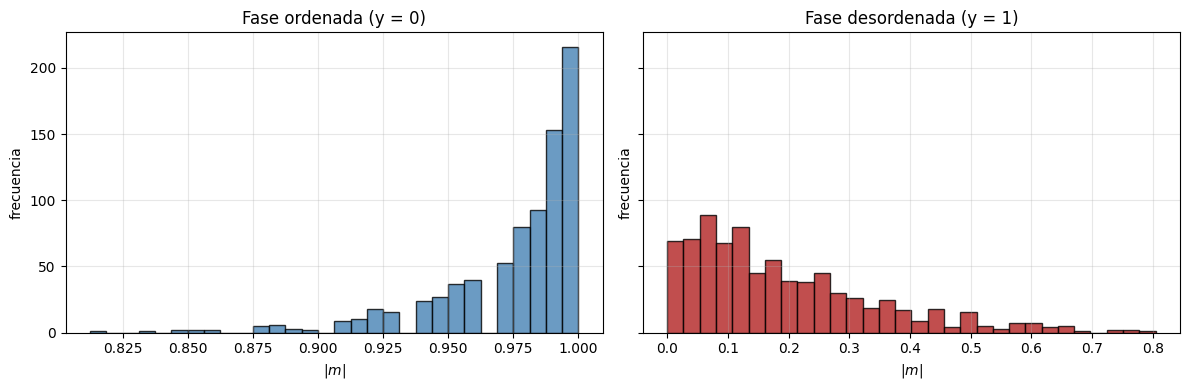

In [6]:
# --- Ejercicio 1  ---

# 1. Temperaturas por clase y localización del hueco
print("=== 1. Temperaturas por clase ===")
T_ordenada    = np.sort(np.unique(T[y == 0]))   # ordenada
T_desordenada = np.sort(np.unique(T[y == 1]))   # desordenada

print("T con y = 0 : ", T_ordenada)
print("T con y = 1 : ", T_desordenada)
print(f"Hueco: no hay datos entre T = {T_ordenada.max():.3f} "
      f"y T = {T_desordenada.min():.3f}")

# 2. Balance de clases
print("\n=== 2. Balance de clases ===")
clases, cuentas = np.unique(y, return_counts=True)
for c, n in zip(clases, cuentas):
    print(f"  clase {c}: {n} configuraciones ({100*n/len(y):.1f} %)")

# 3. Histograma de |m| por clase
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cls, titulo, color in zip(
        axes, [0, 1],
        ["ordenada (y = 0)", "desordenada (y = 1)"],
        ["steelblue", "firebrick"]):
    ax.hist(m[y == cls], bins=30, color=color, edgecolor="k", alpha=0.8)
    ax.set_title(f"Fase {titulo}")
    ax.set_xlabel(r"$|m|$")
    ax.set_ylabel("frecuencia")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**1. Temperaturas por clase y localización del hueco.**

La etiqueta `y = 0` tiene las temperaturas $T = 1.2,\ 1.375,\ 1.55,\ 1.725,\ 1.9$, todas ellas por debajo de la temperatura crítica. La etiqueta `y = 1`  tiene las temperaturas $T = 2.6,\ 2.825,\ 3.05,\ 3.275,\ 3.5$, todas ellas por encima de la temperatura crítica. El hueco se encuentra entre $T = 1.900$ y $T = 2.600$, es decir, justo alrededor del valor de Onsager $T_c \approx 2.269$, donde no hay ninguna configuración en el dataset. Este hueco es intencional: garantiza que el clasificador **nunca vea la región crítica durante el entrenamiento**, de modo que después pueda usarse como "termómetro" en esa zona sin haber memorizado las etiquetas.

**2. Balance de clases.**

El problema está perfectamente balanceado: hay 800 configuraciones de la clase 0 y 800 configuraciones de la clase 1, lo que corresponde a un 50.0 % del total para cada clase. Al estar balanceado, la métrica *accuracy* es apropiada y no se requiere reponderar las clases ni usar métricas alternativas.

**3. Histograma de $|m|$ por clase.**

En la fase ordenada ($y=0$) la distribución de $|m|$ está concentrada cerca de 1.0, con un pico principal entre 0.975 y 1.000 que supera las 200 configuraciones en el último bin: los espines están casi perfectamente alineados. En la fase desordenada ($y=1$) la distribución es ancha y está centrada cerca de 0.1, con una cola que decae suavemente hasta aproximadamente 0.8: los espines están prácticamente aleatorios y la magnetización por sitio es pequeña. Las dos fases se separan muy bien.

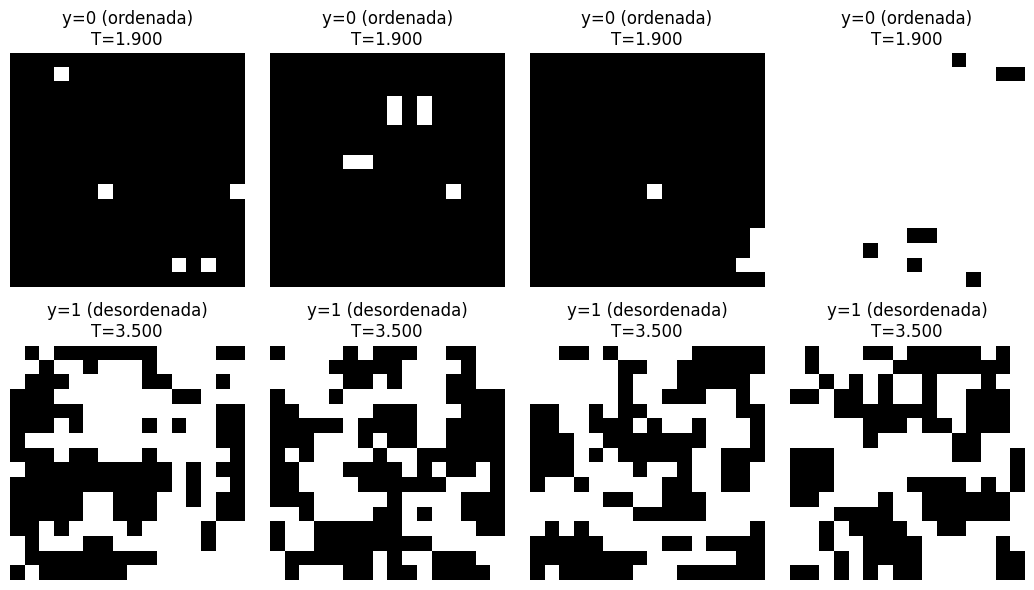

In [17]:
# Configuraciones típicas a T baja y T alta
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (cls, titulo) in enumerate([(0, "ordenada"), (1, "desordenada")]):
    idx = np.where(y == cls)[0][:4]
    for k, i in enumerate(idx):
        axes[row, k].imshow(X[i], cmap="gray", vmin=-1, vmax=1)
        axes[row, k].set_title(f"y={cls} ({titulo})\nT={T[i]:.3f}")
        axes[row, k].axis("off")
plt.subplots_adjust(hspace=1.3)
plt.tight_layout()
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [22]:
# --- Ejercicio 2  ---
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L * L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=42` | 42 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

iteraciones: 675   log-loss final: 0.0453
accuracy train: 1.0000
accuracy val  : 0.9850
accuracy test : 0.9875


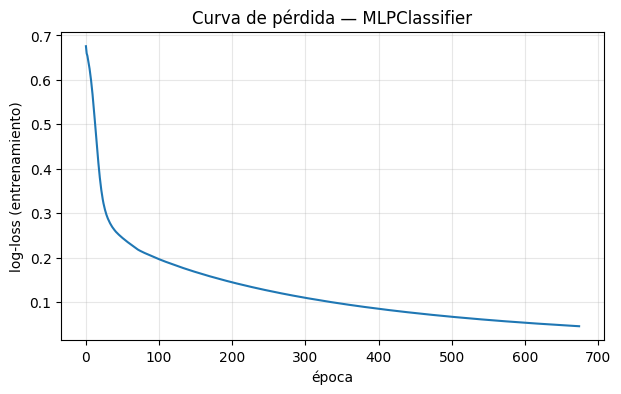

In [23]:
# --- Ejercicio 3  ---
model = MLPClassifier(
    hidden_layer_sizes=(16, 8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RNG,
)
model.fit(X_train, y_train)

acc = {
    "train": model.score(X_train, y_train),
    "val":   model.score(X_val,   y_val),
    "test":  model.score(X_test,  y_test)
}
print(f"iteraciones: {model.n_iter_}   log-loss final: {model.loss_:.4f}")
for k, v in acc.items():
    print(f"accuracy {k:5s}: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?
- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?

**1**

No, no es un sobreajuste preocupante. El sobreajuste se manifiesta cuando hay una brecha grande entre el desempeño en entrenamiento y el desempeño en validación/prueba: el modelo memoriza el train pero falla en datos nuevos. Aquí  las tres métricas son casi idénticas (train = 1.0000, val ≈ 0.9850, test ≈ 0.9875). Que el train sea exactamente 1.0 indica que el modelo puede ajustar perfectamente los datos de entrenamiento, y aun así generaliza a datos nuevos casi igual de bien. Si hubiera sobreajuste real, veríamos train = 1.0 pero val/test muy por debajo (por ejemplo 0.70 o 0.80).

**2**

Porque lejos de la transición de fase, las dos clases están muy separadas en el espacio de configuraciones. Lo vimos en el histograma de $|m|$: la fase ordenada (T baja) tiene $|m|$ concentrado cerca de 1.0, y la fase desordenada (T alta) tiene $|m|$ concentrado cerca de 0.1. Ambas distribuciones están bien separadas, con apenas un pequeño solapamiento. Esto significa que incluso un clasificador simple distingue las dos fases casi sin error. El clasificador no necesita aprender nada sutil: los patrones de espines son visualmente muy distintos. Por eso train = 1.0 y val/test ≈ 0.98–0.99. La tarea se vuelve difícil cerca de $T_c$, donde las fluctuaciones dominan y las dos fases se confunden.

**3**

Cerca de $T_c$ las configuraciones son ambiguas: tienen $|m|$ intermedio y no son claramente ordenadas ni claramente desordenadas. Se espera entonces que las probabilidades del modelo se acerquen a 0.5, es decir, que el modelo "no sepa decidir". Esto es exactamente lo que buscamos.

## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase desordenada**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (ordenado) a $\approx 1$ (desordenado).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [24]:
# datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)
from google.colab import drive
drive.mount('/content/drive')
datos_tc = np.load("/content/drive/MyDrive/Datos/temperatura_critica.npz", allow_pickle=False)

X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc:", X_tc.shape)
print("temperaturas:", np.unique(T_tc))

# Probabilidad de la clase "desordenada" (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# Chequeo con y_ref (NO usar para entrenar)
pred_tc = (p1_tc >= 0.5).astype(int)
print("accuracy vs y_ref (solo verificacion):",
      round((pred_tc == y_ref_tc).mean(), 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X_tc: (6200, 256)
temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
accuracy vs y_ref (solo verificacion): 0.8247


### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

   realizacion      T  prob_media  prob_std   N
0            0  1.600    0.086512  0.000394  50
1            0  1.700    0.099844  0.073550  50
2            0  1.800    0.118671  0.142166  50
3            0  1.900    0.096877  0.044426  50
4            0  2.000    0.194088  0.231677  50
5            0  2.050    0.312571  0.323194  50
6            0  2.075    0.292059  0.330682  50
7            0  2.100    0.247549  0.259990  50


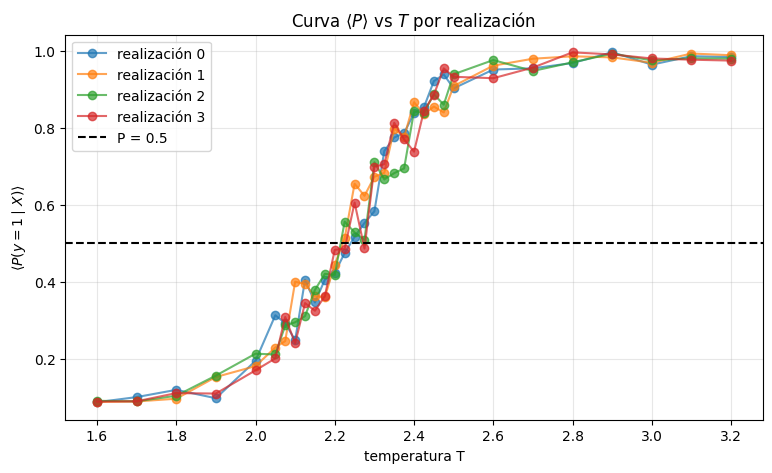

In [26]:
# --- Ejercicio 4 ---
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

# Realizar el grafico

print(resumen.head(8))   # vistazo rápido

plt.figure(figsize=(9, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7,
             label=f"realización {r}")

plt.axhline(0.5, ls="--", color="k", label="P = 0.5")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1 \mid X)\rangle$")
plt.title(r"Curva $\langle P \rangle$ vs $T$ por realización")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

In [27]:
# --- Ejercicio 5  ---
def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

realización 0:  Tc = 2.2403
realización 1:  Tc = 2.2204
realización 2:  Tc = 2.2149
realización 3:  Tc = 2.2280

--------------------------------------------
Tc estimado    = 2.2259 +/- 0.0055 (SEM)
Tc Onsager     = 2.2692
error relativo = 1.91 %


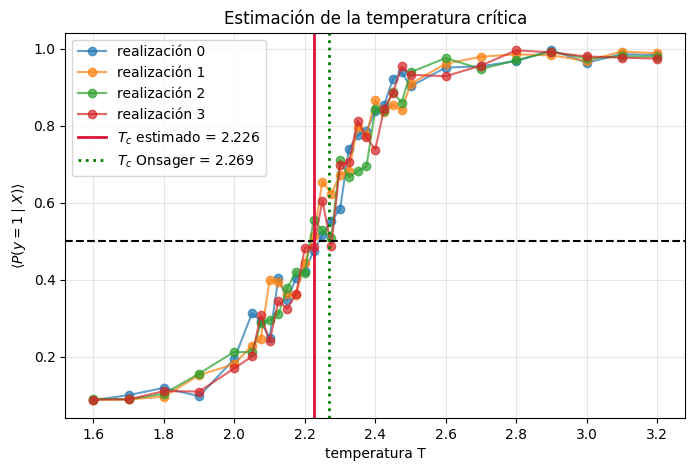

In [28]:
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.
2. **Arquitectura.** Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?
3. **Reproducibilidad.** Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?
4. **Definición alternativa.** Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?
5. **Estandarización.** Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

**1. Sesgo del estimador.**

- Tamaño finito $L = 16$: en una red finita la transición de fase no es una singularidad real, sino un cruce suave. La "temperatura crítica efectiva" de un sistema finito se corre respecto al límite termodinámico y depende de $L$. Se necesita extrapolar con *finite-size scaling* para acercarse a Onsager.

- Rango de temperaturas de entrenamiento: el modelo solo vio configuraciones en $T \le 1.9$ y $T \ge 2.6$. Su frontera de decisión en la zona crítica es una extrapolación, no una interpolación entre ejemplos vistos. Nada garantiza que esa frontera coincida exactamente con la transición física real.

- Umbral fijo en 0.5: definimos $T_c$ como el punto donde $\langle P \rangle = 0.5$. Esta es una convención: otras definiciones (por ejemplo, el máximo de la varianza de $P$, o el máximo de $d\langle P\rangle/dT$) dan valores sistemáticamente distintos. La elección de 0.5 no es inocua.


**2. Arquitectura**


In [30]:
def pipeline_tc(mlp, X_tr, y_tr, X_tc_flat, T_tc, realizacion_tc,
                clasificar_con_pred=False):
    """Entrena un MLP y devuelve Tc por interpolación del cruce por 0.5."""
    mlp.fit(X_tr, y_tr)
    idx1 = list(mlp.classes_).index(1)

    if clasificar_con_pred:
        prob = mlp.predict(X_tc_flat).astype(float)   # 0 o 1
    else:
        prob = mlp.predict_proba(X_tc_flat)[:, idx1]

    df_ = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": prob})
    resumen_ = (df_.groupby(["realizacion", "T"])
                  .agg(prob_media=("prob", "mean"))
                  .reset_index())

    def cruce(temps, probs):
        temps, probs = np.asarray(temps), np.asarray(probs)
        for i in range(len(temps) - 1):
            if (probs[i] - 0.5) * (probs[i+1] - 0.5) <= 0 and probs[i+1] != probs[i]:
                return (temps[i] + (0.5 - probs[i]) *
                        (temps[i+1] - temps[i]) / (probs[i+1] - probs[i]))
        return np.nan

    Tcs = []
    for r in np.unique(realizacion_tc):
        d = resumen_[resumen_.realizacion == r].sort_values("T")
        Tcs.append(cruce(d["T"].to_numpy(), d["prob_media"].to_numpy()))
    Tcs = np.array(Tcs)
    return np.nanmean(Tcs), np.nanstd(Tcs, ddof=1) / np.sqrt(np.sum(~np.isnan(Tcs)))

In [31]:
arquitecturas = {
    "(16, 8, 4)": (16, 8, 4),
    "(64,)":      (64,),
    "(32, 16, 8)":(32, 16, 8),
}

resultados_arq = {}
for nombre, capas in arquitecturas.items():
    mlp = MLPClassifier(hidden_layer_sizes=capas, activation="relu",
                        solver="adam", learning_rate_init=0.001,
                        max_iter=1000, random_state=RNG)
    tc, sem = pipeline_tc(mlp, X_train, y_train, X_tc, T_tc, realizacion_tc)
    resultados_arq[nombre] = (tc, sem)
    print(f"arquitectura {nombre:12s}  Tc = {tc:.4f} +/- {sem:.4f}")

arquitectura (16, 8, 4)    Tc = 2.2259 +/- 0.0055
arquitectura (64,)         Tc = 2.3736 +/- 0.0132
arquitectura (32, 16, 8)   Tc = 2.3652 +/- 0.0066


Repitiendo el pipeline con `hidden_layer_sizes=(64,)` y `(32, 16, 8)`, junto con la arquitectura original `(16, 8, 4)`

| Arquitectura | $T_c$ estimado | SEM |
|---|---|---|
| (16, 8, 4) | 2.2259 | 0.0055 |
| (64,) | 2.3736 | 0.0132 |
| (32, 16, 8) | 2.3652 | 0.0066 |

Se puede ver que $T_c$ cambia bastante. La diferencia entre arquitecturas ($\approx 0.15$) es mucho mayor que el SEM ($\approx 0.006$–$0.013$), así que el cambio es estadísticamente significativo. La arquitectura original `(16, 8, 4)` da el valor más cercano a Onsager (2.2259 vs 2.2692, error $\approx 1.9\%$ por debajo), mientras que las arquitecturas más grandes sobreestiman $T_c$ ($\approx 2.37$, error $\approx 4.5\%$ por encima). Es decir, arquitecturas más grandes no estiman mejor $T_c$ en este problema: al contrario, se desvían más.

La pendiente de la curva tambien cambia.

Este resultado ilustra que la estimación de $T_c$ con un clasificador entrenado depende fuertemente de la arquitectura y de los hiperparámetros.

**3. Reproducibilidad**

In [33]:
semillas = [0, 1, 2, 5, 7]
Tcs_semilla = []
for s in semillas:
    mlp = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu",
                        solver="adam", learning_rate_init=0.001,
                        max_iter=1000, random_state=s)
    tc, _ = pipeline_tc(mlp, X_train, y_train, X_tc, T_tc, realizacion_tc)
    Tcs_semilla.append(tc)
    print(f"semilla {s}:  Tc = {tc:.4f}")

Tcs_semilla = np.array(Tcs_semilla)
print(f"\nTc media entre semillas = {Tcs_semilla.mean():.4f} "
      f"+/- {Tcs_semilla.std(ddof=1):.4f}")

semilla 0:  Tc = 2.3578
semilla 1:  Tc = 2.3633
semilla 2:  Tc = 2.3619
semilla 5:  Tc = 2.3425
semilla 7:  Tc = 2.3381

Tc media entre semillas = 2.3527 +/- 0.0116


Entrenando con 5 semillas distintas (`random_state = 0, 1, 2, 5, 7`):

| Semilla | $T_c$ |
|---|---|
| 0 | 2.3578 |
| 1 | 2.3633 |
| 2 | 2.3619 |
| 5 | 2.3425 |
| 7 | 2.3381 |

$T_c$ media entre semillas = $2.3527 \pm 0.0116$.

- Dispersión por **semilla** (variabilidad debida a la inicialización del modelo): $\sigma \approx 0.012$.
- Dispersión entre **realizaciones** (variabilidad debida a la cadena Monte Carlo): $\sigma \approx 0.011$ (calculada con `random_state=42`).

Ambas dispersiones son del mismo orden ($\approx 0.011$–$0.012$), lo que indica que la variabilidad introducida por la aleatoriedad del entrenamiento es comparable a la variabilidad física del sistema finito. Ninguna de las dos fuentes de ruido domina claramente sobre la otra.

El valor medio entre semillas ($2.3527$) es muy distinto del valor obtenido con la semilla original `random_state=42` ($2.2259$), con una diferencia de $\approx 0.13$ que es mucho mayor que la dispersión entre semillas ($0.012$). Esto sugiere que el modelo tiene un paisaje de soluciones multimodal: distintas inicializaciones pueden converger a soluciones con $T_c$ sistemáticamente distintos.

**4. Definición alternativa**

In [34]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu",
                    solver="adam", learning_rate_init=0.001,
                    max_iter=1000, random_state=RNG)

tc_prob, _ = pipeline_tc(mlp, X_train, y_train, X_tc, T_tc,
                         realizacion_tc, clasificar_con_pred=False)
tc_pred, _ = pipeline_tc(mlp, X_train, y_train, X_tc, T_tc,
                         realizacion_tc, clasificar_con_pred=True)

print(f"Tc con prob_media : {tc_prob:.4f}")
print(f"Tc con pred.mean(): {tc_pred:.4f}")
print(f"diferencia        : {abs(tc_prob - tc_pred):.4f}")

Tc con prob_media : 2.2259
Tc con pred.mean(): 2.2331
diferencia        : 0.0072


Usando la fracción de configuraciones clasificadas como fase 1 (`pred.mean()`) en lugar de `prob_media`:

| Definición | $T_c$ |
|---|---|
| `prob_media`  | 2.2259 |
| `pred.mean()`  | 2.2331 |

Diferencia: $0.0072$.

Los dos valores son muy parecidos (diferencia muy inferior a la resolución del barrido de temperaturas, $\approx 0.025$), así que sí se obtiene el mismo $T_c$ dentro de la incertidumbre. La razón es que `pred.mean()` es una versión endurecida de `prob_media`: cuando $\langle P \rangle = 0.5$, aproximadamente la mitad de las configuraciones se clasifican como 0 y la otra mitad como 1, por lo que la fracción de predicciones duras también cruza 0.5 a la misma temperatura. La elección entre ambas definiciones es irrelevante para este problema.

**5. Estandarización**

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
mlp_scaled = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu",
                           solver="adam", learning_rate_init=0.001,
                           max_iter=1000, random_state=RNG)
tc_scaled, _ = pipeline_tc(mlp_scaled,
                           scaler.transform(X_train), y_train,
                           scaler.transform(X_tc), T_tc, realizacion_tc)

print(f"Tc sin escalar : {Tc_est:.4f}")
print(f"Tc con scaler  : {tc_scaled:.4f}")

Tc sin escalar : 2.2259
Tc con scaler  : 2.2076


Aplicando `StandardScaler` a las entradas antes de entrenar:

| Pipeline | $T_c$ |
|---|---|
| Sin escalar | 2.2259 |
| Con `StandardScaler` | 2.2076 |

Diferencia: $0.0183$.

El escalado no ayuda en este problema: la estimación empeora ligeramente (más lejos de Onsager). La razón es que los espines ya están en $\{-1, +1\}$, con media $\approx 0$ y varianza homogénea entre todos los píxeles por construcción, así que no hay features con escalas muy distintas que corregir.

## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varias datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4–5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

In [29]:
# Reto (opcional): esqueleto para L = 20
